## Human Feedback in Loop

In [24]:
from langchain_tavily import TavilySearch

from langchain_groq import ChatGroq
from langchain_core.tools import tool

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode,tools_condition

from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import display,Image

from langgraph.types import Command,interrupt


In [30]:
llm = ChatGroq( model="openai/gpt-oss-120b")

class State(TypedDict):
    messages : Annotated[list,add_messages]

graph_builder = StateGraph(State)

@tool 
def humman_assistant(query : str) -> str:
    """ Request assistance from human operator"""
    human_response = interrupt({"query" : query})
    return human_response["data"]

search_tool = TavilySearch(max_results=2)
tools = [search_tool,humman_assistant]

llm_with_tools = llm.bind_tools(tools)

# node creation
def chatbot(state: State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

tool_node = ToolNode(tools=tools)

# add node 
graph_builder.add_node("chatbot",chatbot)
graph_builder.add_node("tools",tool_node)

# add edges
graph_builder.add_edge(START,"chatbot")
graph_builder.add_conditional_edges("chatbot",tools_condition)
graph_builder.add_edge("tools","chatbot")




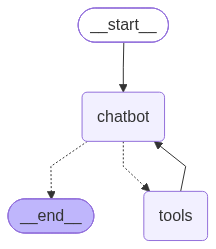

In [31]:
# Add memory ,compile and visualize the graph
memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
user_input = "I need some expert guidance and assistance for building an AI Agent. Request assistance from human operator?"

config = {
    "configurable": {
        "thread_id": "1"
    }
}

events = graph.stream(
    {"messages": [("user", user_input)]},
    config=config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()


================================ Human Message =================================

I need some expert guidance and assistance for building an AI Agent. Request assistance from human operator?
================================== Ai Message ==================================
Tool Calls:
  humman_assistant (fc_17913c4c-b3b4-43be-9960-40c4fd6274d4)
 Call ID: fc_17913c4c-b3b4-43be-9960-40c4fd6274d4
  Args:
    query: User requests expert guidance and assistance for building an AI Agent. Provide detailed help, resources, best practices, and any needed clarification.
================================== Ai Message ==================================
Tool Calls:
  humman_assistant (fc_17913c4c-b3b4-43be-9960-40c4fd6274d4)
 Call ID: fc_17913c4c-b3b4-43be-9960-40c4fd6274d4
  Args:
    query: User requests expert guidance and assistance for building an AI Agent. Provide detailed help, resources, best practices, and any needed clarification.


In [33]:
humman_response = "Use langGraph to build an AI Agent. It provides a framework for creating conversational agents with memory and tool integration."

humman_command = Command(resume = {"data" : humman_response})

events = graph.stream(
    humman_command,
    config=config,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()


================================== Ai Message ==================================
Tool Calls:
  humman_assistant (fc_17913c4c-b3b4-43be-9960-40c4fd6274d4)
 Call ID: fc_17913c4c-b3b4-43be-9960-40c4fd6274d4
  Args:
    query: User requests expert guidance and assistance for building an AI Agent. Provide detailed help, resources, best practices, and any needed clarification.
================================= Tool Message =================================
Name: humman_assistant

Use langGraph to build an AI Agent. It provides a framework for creating conversational agents with memory and tool integration.
================================== Ai Message ==================================

Below is a **step‑by‑step guide** (with code snippets, resources, and best‑practice tips) for building a production‑ready AI Agent using **LangChain / LangGraph**. The workflow is broken into four phases:

1. **Planning & Architecture**
2. **Implementation (core agent, memory, tools, routing)**
3. **Testing, 